## Problem 3
Write a Python program to perform geometric transformations (resizing/zooming, rotation, translation).


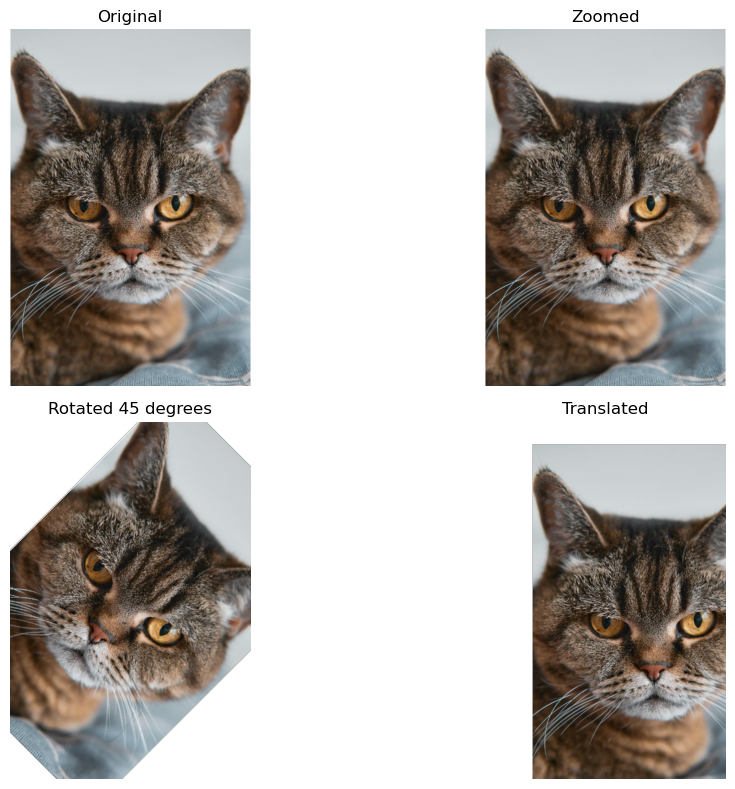

In [3]:
import matplotlib.pyplot as plt
import numpy as np

image = plt.imread("cat.png")
# 1. Resize / Zoom (2 times), manually
height, width, channels = image.shape
zoomed = np.zeros((height * 2, width * 2, channels), dtype=image.dtype)
for row in range(height):
    for col in range(width):
        zoomed[row * 2, col * 2] = image[row, col]
        zoomed[row * 2 + 1, col * 2] = image[row, col]
        zoomed[row * 2, col * 2 + 1] = image[row, col]
        zoomed[row * 2 + 1, col * 2 + 1] = image[row, col]

# 2. Rotation (45 degrees anticlockwise), manually
rotated = np.zeros_like(image)
angle = np.pi / 4
cos_angle = np.cos(angle)
sin_angle = np.sin(angle)
center_x = width / 2
center_y = height / 2
for row in range(height):
    for col in range(width):
        x = col - center_x
        y = row - center_y
        source_col = int(cos_angle * x + sin_angle * y + center_x)
        source_row = int(-sin_angle * x + cos_angle * y + center_y)
        if 0 <= source_row < height and 0 <= source_col < width:
            rotated[row, col] = image[source_row, source_col]

# 3. Translation (100 pixels right and 50 pixels down), manually
translated = np.zeros_like(image)
for row in range(height):
    for col in range(width):
        new_row = row + 50
        new_col = col + 100
        if new_row < height and new_col < width:
            translated[new_row, new_col] = image[row, col]

# Display results
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(image)
plt.title("Original")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(zoomed)
plt.title("Zoomed")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(rotated)
plt.title("Rotated 45 degrees")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(translated)
plt.title("Translated")
plt.axis("off")

plt.tight_layout()
plt.show()
